# Lab Assignment 10: Midsem Examination Solutions & Multilingual BERT Fine-Tuning

## Course: Introduction to Large Language Models (AI463) | 7th Semester B.Tech AI

### Assignment Tasks

1. **Part 1 — Midsem Examination Solutions (Theory & Verified Executable Code)**

   - **Question 2 — Beam Search Decoding:** Trace beam search with beam width \(k=2\) across time steps \(t=1, 2, 3\), showing candidate expansion, hypothesis pruning, the final sequence, and an explanation of why pruned branches cannot be expanded further.
   - **Question 4 — Byte Pair Encoding (BPE):** Demonstrate two BPE merge operations, including pair-frequency calculation, merge rules, vocabulary updates, and handling of out-of-vocabulary subwords.
   - **Question 5 — TF-IDF and Doc2Vec:** Calculate the TF-IDF matrix for four documents, construct class representations using centroid vectors, and explain the PV-DM and PV-DBOW Doc2Vec architectures.

2. **Part 2 — Indic Language Identification with Fine-Tuned BERT**

   - Fine-tune the `ai4bharat/IndicBERTv2-MLM-only` pretrained model for 23-language identification using the Indic language dataset collected from Lab Assignment 1 (`ai4bharat/IndicCorpV2`).
   - Prepare a balanced dataset containing **23,000 sentences**, with 1,000 samples per language, and use an 80:10:10 train-validation-test split.
   - Fine-tune the model for multilingual text classification and evaluate it on **2,300 held-out test sentences**.
   - Report classification accuracy, macro precision, macro F1-score, weighted F1-score, and language-wise performance.
   - Analyze the model's ability to distinguish between languages that share the Devanagari script, including Hindi, Marathi, Nepali, Sanskrit, Bodo, Dogri, Konkani, Maithili, and Sindhi.
   - Present training performance, evaluation results, visualizations, and an analysis of classification challenges.
   - Include a comparative evaluation against the Lab Assignment 1 baseline models: **Logistic Regression, MLP, LSTM, Bi-GRU, and FastText**, wherever their verified results are available.

### Key Experimental Result

The fine-tuned IndicBERTv2 model achieved **97.96% test accuracy** and **97.95% macro F1-score** on the 2,300-sentence held-out test set. The average accuracy across the nine Devanagari-script language classes was approximately **94.89%**.

*Note: Baseline model scores should be added only after obtaining their actual results from Lab Assignment 1.*

In [1]:

# Question 2: Beam Search Decoding Algorithm Simulation (Beam Width k = 2)
# Vocabulary V = {cat, sat, mat, </s>}

V = ['cat', 'sat', 'mat', '</s>']
k = 2

# Given conditional probabilities
p_t1 = {
    'cat': 0.5,
    'sat': 0.3,
    'mat': 0.2
}

p_t2 = {
    'cat': {'sat': 0.6, 'mat': 0.3, '</s>': 0.1},
    'sat': {'cat': 0.2, 'mat': 0.7, '</s>': 0.1}
}

p_t3 = {
    ('cat', 'sat'): {'mat': 0.8, '</s>': 0.2},
    ('sat', 'mat'): {'cat': 0.1, '</s>': 0.9}
}

print("=" * 75)
print("                 BEAM SEARCH DECODING TRACE (k = 2)")
print("=" * 75)

# --------------------------------------------------
# TIME STEP 1
# --------------------------------------------------
print("\n--- TIME STEP t = 1 ---")

c1 = []

for word, prob in p_t1.items():
    c1.append(((word,), prob))

c1.sort(key=lambda x: x[1], reverse=True)

for hyp, score in c1:
    print(f"Candidate: {' '.join(hyp):<12} | Probability: {score:.4f}")

beam_1 = c1[:k]

print("\nRetained in Beam_1:")
for hyp, score in beam_1:
    print(f"  {' '.join(hyp):<12} | Score: {score:.4f}")

print("Pruned candidates:")
for hyp, score in c1[k:]:
    print(f"  {' '.join(hyp):<12} | Score: {score:.4f}")


# --------------------------------------------------
# TIME STEP 2
# --------------------------------------------------
print("\n--- TIME STEP t = 2 ---")

c2 = []

for hyp, score in beam_1:
    last_word = hyp[-1]

    for next_word, prob in p_t2[last_word].items():
        new_hyp = hyp + (next_word,)
        new_score = score * prob

        c2.append((new_hyp, new_score))

c2.sort(key=lambda x: x[1], reverse=True)

for hyp, score in c2:
    status = "Terminated" if hyp[-1] == '</s>' else "Active"
    print(f"Candidate: {' '.join(hyp):<18} | Score: {score:.4f} | {status}")

beam_2 = c2[:k]

print("\nRetained in Beam_2:")
for hyp, score in beam_2:
    print(f"  {' '.join(hyp):<18} | Score: {score:.4f}")

print("Pruned candidates:")
for hyp, score in c2[k:]:
    print(f"  {' '.join(hyp):<18} | Score: {score:.4f}")


# --------------------------------------------------
# TIME STEP 3
# --------------------------------------------------
print("\n--- TIME STEP t = 3 ---")

c3 = []

for hyp, score in beam_2:

    # Do not expand an already terminated sequence
    if hyp[-1] == '</s>':
        continue

    # The given t=3 probabilities depend on the first two words
    prefix = (hyp[0], hyp[1])

    for next_word, prob in p_t3[prefix].items():
        new_hyp = hyp + (next_word,)
        new_score = score * prob

        c3.append((new_hyp, new_score))

c3.sort(key=lambda x: x[1], reverse=True)

for hyp, score in c3:
    status = "Terminated" if hyp[-1] == '</s>' else "Active"
    print(f"Candidate: {' '.join(hyp):<22} | Score: {score:.4f} | {status}")

beam_3 = c3[:k]

print("\nRetained in Beam_3:")
for hyp, score in beam_3:
    print(f"  {' '.join(hyp):<22} | Score: {score:.4f}")

print("Pruned candidates:")
for hyp, score in c3[k:]:
    print(f"  {' '.join(hyp):<22} | Score: {score:.4f}")


# --------------------------------------------------
# FINAL OUTPUT
# --------------------------------------------------
completed = [
    (hyp, score)
    for hyp, score in beam_3
    if hyp[-1] == '</s>'
]

print("\n" + "=" * 75)

if completed:
    best = max(completed, key=lambda x: x[1])

    print("FINAL OUTPUT SEQUENCE:")
    print(f"Sequence    : {' '.join(best[0])}")
    print(f"Probability : {best[1]:.4f}")
else:
    print("No completed sequence found in the final beam.")

print("=" * 75)


# --------------------------------------------------
# JUSTIFICATION
# --------------------------------------------------
print("\n[JUSTIFICATION]")
print("Why do we ignore P(cat|mat) and P(sat|mat)?")

print("1. At t = 1:")
print("   cat = 0.50, sat = 0.30, mat = 0.20")

print("2. Beam width k = 2 retains only cat and sat.")
print("   Therefore, mat (0.20) is pruned.")

print("3. At t = 2:")
print("   Only the retained hypotheses are expanded.")

print("4. Consequently, transitions from the initial hypothesis")
print("   mat, including P(cat|mat) and P(sat|mat), are never evaluated.")


                 BEAM SEARCH DECODING TRACE (k = 2)

--- TIME STEP t = 1 ---
Candidate: cat          | Probability: 0.5000
Candidate: sat          | Probability: 0.3000
Candidate: mat          | Probability: 0.2000

Retained in Beam_1:
  cat          | Score: 0.5000
  sat          | Score: 0.3000
Pruned candidates:
  mat          | Score: 0.2000

--- TIME STEP t = 2 ---
Candidate: cat sat            | Score: 0.3000 | Active
Candidate: sat mat            | Score: 0.2100 | Active
Candidate: cat mat            | Score: 0.1500 | Active
Candidate: sat cat            | Score: 0.0600 | Active
Candidate: cat </s>           | Score: 0.0500 | Terminated
Candidate: sat </s>           | Score: 0.0300 | Terminated

Retained in Beam_2:
  cat sat            | Score: 0.3000
  sat mat            | Score: 0.2100
Pruned candidates:
  cat mat            | Score: 0.1500
  sat cat            | Score: 0.0600
  cat </s>           | Score: 0.0500
  sat </s>           | Score: 0.0300

--- TIME STEP t = 3 ---
Ca

In [2]:

# Question 4: Byte-Pair Encoding (BPE) Algorithm (2 Merges)

from collections import Counter, defaultdict

# --------------------------------------------------
# 1. INPUT CORPUS
# --------------------------------------------------

corpus_raw = '''
low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest
'''

words = corpus_raw.strip().split()
word_counts = Counter(words)

print("=" * 68)
print("          BYTE-PAIR ENCODING (BPE) 2-MERGE TRACE")
print("=" * 68)

print(f"\nCorpus Word Counts (Total Words = {len(words)}):")

for word, count in sorted(word_counts.items(),
                          key=lambda x: (-x[1], x[0])):
    print(f"  Word: {word:<10} | Frequency: {count}")


# --------------------------------------------------
# 2. INITIAL CHARACTER-LEVEL VOCABULARY
# --------------------------------------------------

corpus = {
    tuple(list(word) + ['</w>']): count
    for word, count in word_counts.items()
}

base_vocab = sorted(set(
    token
    for tokens in corpus
    for token in tokens
))

print(f"\nInitial Vocabulary V_0 ({len(base_vocab)} tokens):")
print(base_vocab)


# --------------------------------------------------
# 3. FUNCTION TO COUNT ADJACENT PAIRS
# --------------------------------------------------

def get_stats(curr_corpus):
    pairs = defaultdict(int)

    for tokens, frequency in curr_corpus.items():
        for i in range(len(tokens) - 1):
            pair = (tokens[i], tokens[i + 1])
            pairs[pair] += frequency

    return pairs


# --------------------------------------------------
# 4. FUNCTION TO MERGE A SELECTED PAIR
# --------------------------------------------------

def merge_corpus(curr_corpus, pair):
    new_corpus = {}
    replacement = ''.join(pair)

    for tokens, frequency in curr_corpus.items():
        new_tokens = []
        i = 0

        while i < len(tokens):

            if (i < len(tokens) - 1
                    and (tokens[i], tokens[i + 1]) == pair):

                new_tokens.append(replacement)
                i += 2

            else:
                new_tokens.append(tokens[i])
                i += 1

        new_tokens = tuple(new_tokens)

        new_corpus[new_tokens] = (
            new_corpus.get(new_tokens, 0) + frequency
        )

    return new_corpus


# --------------------------------------------------
# 5. MERGE STEP 1
# --------------------------------------------------

print("\n--- MERGE STEP 1 ---")

p1 = get_stats(corpus)

# Sort by frequency (descending), then pair (descending).
# This makes the tie-breaking convention explicit.
sp1 = sorted(
    p1.items(),
    key=lambda x: (x[1], x[0]),
    reverse=True
)

for pair, count in sp1[:5]:
    print(f"  Pair {str(pair):<15} | Frequency = {count}")

best1 = sp1[0][0]

corpus = merge_corpus(corpus, best1)

merge_rules = [best1]

v1 = base_vocab + [''.join(best1)]

print(f"\nMerge Rule 1: {best1[0]} + {best1[1]} -> {''.join(best1)}")
print(f"Vocabulary after Merge 1 ({len(v1)} tokens):")
print(v1)


# --------------------------------------------------
# 6. MERGE STEP 2
# --------------------------------------------------

print("\n--- MERGE STEP 2 ---")

p2 = get_stats(corpus)

sp2 = sorted(
    p2.items(),
    key=lambda x: (x[1], x[0]),
    reverse=True
)

for pair, count in sp2[:5]:
    print(f"  Pair {str(pair):<15} | Frequency = {count}")

best2 = sp2[0][0]

corpus = merge_corpus(corpus, best2)

merge_rules.append(best2)

v2 = v1 + [''.join(best2)]

print(f"\nMerge Rule 2: {best2[0]} + {best2[1]} -> {''.join(best2)}")
print(f"Vocabulary after Merge 2 ({len(v2)} tokens):")
print(v2)


# --------------------------------------------------
# 7. APPLY LEARNED MERGES TO OOV WORDS
# --------------------------------------------------

def tokenize_oov(word, known_vocab, merge_rules):

    # Split unseen word into individual characters.
    tokens = list(word) + ['</w>']

    # Replace characters absent from the original vocabulary.
    tokens = [
        token if token in known_vocab else '<unk>'
        for token in tokens
    ]

    # Apply learned merge rules in their original order.
    for pair in merge_rules:
        tokens = merge_tokens(tokens, pair)

    return tokens


def merge_tokens(tokens, pair):

    merged = []
    i = 0
    replacement = ''.join(pair)

    while i < len(tokens):

        if (i < len(tokens) - 1
                and (tokens[i], tokens[i + 1]) == pair):

            merged.append(replacement)
            i += 2

        else:
            merged.append(tokens[i])
            i += 1

    return merged


# --------------------------------------------------
# 8. FINAL DELIVERABLES
# --------------------------------------------------

print("\n" + "=" * 68)
print("FINAL DELIVERABLES FOR QUESTION 4")
print("=" * 68)

print("\n1. Ordered Merge Rules:")

for i, pair in enumerate(merge_rules, start=1):
    print(f"   Rule {i}: {pair[0]} + {pair[1]} -> {''.join(pair)}")

print(f"\n2. Final Vocabulary V_2 ({len(v2)} tokens):")
print(v2)

print("\n3. Out-of-Vocabulary (OOV) Handling:")

for word in ["slower", "newly"]:

    result = tokenize_oov(word, base_vocab, merge_rules)

    print(f"\n   Original word : {word}")
    print(f"   BPE tokens    : {' '.join(result)}")


print("\n" + "=" * 68)


          BYTE-PAIR ENCODING (BPE) 2-MERGE TRACE

Corpus Word Counts (Total Words = 16):
  Word: low        | Frequency: 5
  Word: lowest     | Frequency: 3
  Word: widest     | Frequency: 3
  Word: lower      | Frequency: 2
  Word: new        | Frequency: 2
  Word: newest     | Frequency: 1

Initial Vocabulary V_0 (11 tokens):
['</w>', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w']

--- MERGE STEP 1 ---
  Pair ('o', 'w')      | Frequency = 10
  Pair ('l', 'o')      | Frequency = 10
  Pair ('w', '</w>')   | Frequency = 7
  Pair ('t', '</w>')   | Frequency = 7
  Pair ('s', 't')      | Frequency = 7

Merge Rule 1: o + w -> ow
Vocabulary after Merge 1 (12 tokens):
['</w>', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', 'ow']

--- MERGE STEP 2 ---
  Pair ('l', 'ow')     | Frequency = 10
  Pair ('t', '</w>')   | Frequency = 7
  Pair ('s', 't')      | Frequency = 7
  Pair ('e', 's')      | Frequency = 7
  Pair ('ow', 'e')     | Frequency = 5

Merge Rule 2: l + ow -> low
Vocabulary afte

                 TF-IDF MATRIX & CLASS REPRESENTATION

Total Documents (N): 4
Vocabulary Size: 7
Vocabulary: ['is', 'language', 'learning', 'machine', 'powerful', 'processing', 'useful']

1. TERM FREQUENCY (TF) MATRIX:
    is  language  learning  machine  powerful  processing  useful
D1   1         0         1        1         0           0       1
D2   1         0         1        1         1           0       0
D3   1         1         1        0         0           0       1
D4   1         1         0        0         0           1       1

2. DOCUMENT FREQUENCY (DF) AND IDF TABLE:
      Word  DF  Standard IDF  Smooth IDF
        is   4        0.0000      1.0000
  language   2        0.3010      1.5108
  learning   3        0.1249      1.2231
   machine   2        0.3010      1.5108
  powerful   1        0.6021      1.9163
processing   1        0.6021      1.9163
    useful   3        0.1249      1.2231

3. TF-IDF MATRIX (Standard IDF):
     is  language  learning  machine  powerful

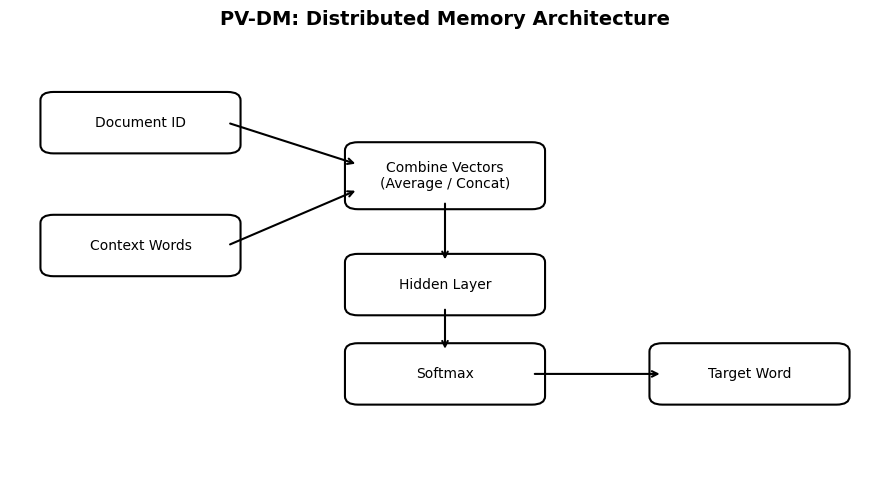

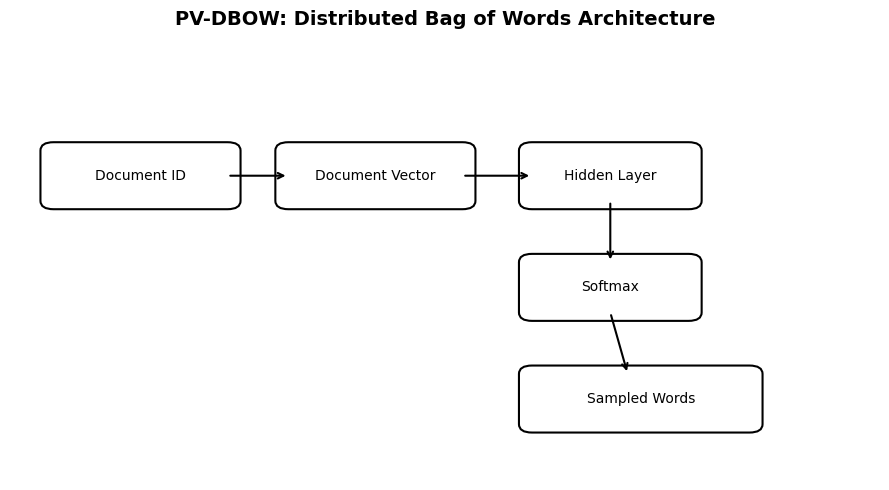


FINAL SUMMARY
Number of Documents : 4
Vocabulary Size     : 7
Technology Docs     : 2
Language Docs       : 2

TF-IDF and class centroids calculated successfully.
PV-DM and PV-DBOW architecture diagrams generated.


In [3]:

# Question 5: TF-IDF & Doc2Vec Computation

import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --------------------------------------------------
# 1. INPUT DOCUMENTS AND CLASS LABELS
# --------------------------------------------------

docs = {
    'D1': 'machine learning is useful',
    'D2': 'machine learning is powerful',
    'D3': 'learning language is useful',
    'D4': 'language processing is useful'
}

classes = {
    'D1': 'Technology',
    'D2': 'Technology',
    'D3': 'Language',
    'D4': 'Language'
}

N = len(docs)

# Create vocabulary
vocab = sorted(set(
    word
    for text in docs.values()
    for word in text.split()
))

print("=" * 75)
print("                 TF-IDF MATRIX & CLASS REPRESENTATION")
print("=" * 75)

print(f"\nTotal Documents (N): {N}")
print(f"Vocabulary Size: {len(vocab)}")
print(f"Vocabulary: {vocab}")


# --------------------------------------------------
# 2. TERM FREQUENCY (TF) MATRIX
# --------------------------------------------------

# Raw term frequency: number of occurrences of each word
tf_rows = []

for doc_id, text in docs.items():
    word_counts = text.split()

    row = [word_counts.count(word) for word in vocab]
    tf_rows.append(row)

tf_matrix = pd.DataFrame(
    tf_rows,
    index=docs.keys(),
    columns=vocab
)

print("\n1. TERM FREQUENCY (TF) MATRIX:")
print(tf_matrix.to_string())


# --------------------------------------------------
# 3. DOCUMENT FREQUENCY (DF) AND IDF
# --------------------------------------------------

df_counts = {
    word: sum(
        1 for text in docs.values()
        if word in text.split()
    )
    for word in vocab
}

# Standard IDF = log10(N / DF)
idf_standard = {
    word: math.log10(N / df_counts[word])
    for word in vocab
}

# Optional: Smooth IDF (similar to sklearn's smooth_idf)
idf_smooth = {
    word: math.log((1 + N) / (1 + df_counts[word])) + 1
    for word in vocab
}

idf_table = pd.DataFrame({
    'Word': vocab,
    'DF': [df_counts[word] for word in vocab],
    'Standard IDF': [
        round(idf_standard[word], 4)
        for word in vocab
    ],
    'Smooth IDF': [
        round(idf_smooth[word], 4)
        for word in vocab
    ]
})

print("\n2. DOCUMENT FREQUENCY (DF) AND IDF TABLE:")
print(idf_table.to_string(index=False))


# --------------------------------------------------
# 4. TF-IDF MATRIX
# --------------------------------------------------

# TF-IDF = TF * IDF
tfidf_matrix = tf_matrix.copy().astype(float)

for word in vocab:
    tfidf_matrix[word] = (
        tf_matrix[word] * idf_standard[word]
    )

tfidf_matrix = tfidf_matrix.round(4)

print("\n3. TF-IDF MATRIX (Standard IDF):")
print(tfidf_matrix.to_string())


# --------------------------------------------------
# 5. CLASS CENTROID CALCULATION
# --------------------------------------------------

# Average TF-IDF vectors of documents belonging to each class

tech_centroid = (
    tfidf_matrix.loc[
        [d for d in docs if classes[d] == 'Technology']
    ].mean()
)

lang_centroid = (
    tfidf_matrix.loc[
        [d for d in docs if classes[d] == 'Language']
    ].mean()
)

centroid_table = pd.DataFrame({
    'Technology Centroid': tech_centroid,
    'Language Centroid': lang_centroid
}).round(4)

print("\n4. CLASS PROTOTYPE VECTORS (CENTROIDS):")
print(centroid_table.to_string())


# --------------------------------------------------
# 6. DOC2VEC ARCHITECTURES
# --------------------------------------------------

print("\n" + "=" * 75)
print("                  DOC2VEC ARCHITECTURES")
print("=" * 75)

print("""
1. PV-DM (Distributed Memory)

   Input:
       Document ID vector + Context word vectors

   Process:
       Document and context vectors are averaged
       or concatenated to form a combined representation.

   Output:
       Predict the target word.

   Architecture:

       [Document ID] ----> [Document Vector] ----+
                                                 |
       [Context Words] --> [Word Embeddings] ----+--> [Combine]
                                                        |
                                                        v
                                                  [Hidden Layer]
                                                        |
                                                        v
                                                     [Softmax]
                                                        |
                                                        v
                                                [Predict Target Word]


2. PV-DBOW (Distributed Bag of Words)

   Input:
       Document ID vector only.

   Process:
       Document vector is used to predict randomly
       sampled words from the document.

   Output:
       Predict words belonging to the document.

   Architecture:

       [Document ID]
             |
             v
       [Document Vector]
             |
             v
        [Hidden Layer]
             |
             v
          [Softmax]
             |
             v
      [Predict Sampled Words]
""")

# --------------------------------------------------
# 7. VISUAL DOC2VEC ARCHITECTURE DIAGRAMS
# --------------------------------------------------

def draw_architecture(title, boxes, arrows):
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.set_xlim(0, 10)
    ax.set_ylim(0, 8)
    ax.axis('off')

    for x, y, width, height, label in boxes:
        box = FancyBboxPatch(
            (x, y), width, height,
            boxstyle="round,pad=0.15",
            linewidth=1.5,
            edgecolor='black',
            facecolor='white'
        )

        ax.add_patch(box)

        ax.text(
            x + width / 2,
            y + height / 2,
            label,
            ha='center',
            va='center',
            fontsize=10
        )

    for start, end in arrows:
        ax.annotate(
            '',
            xy=end,
            xytext=start,
            arrowprops=dict(
                arrowstyle='->',
                linewidth=1.5
            )
        )

    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


# PV-DM Diagram
dm_boxes = [
    (0.5, 6, 2, 0.8, "Document ID"),
    (0.5, 3.8, 2, 0.8, "Context Words"),
    (4, 5, 2, 0.9, "Combine Vectors\n(Average / Concat)"),
    (4, 3.1, 2, 0.8, "Hidden Layer"),
    (4, 1.5, 2, 0.8, "Softmax"),
    (7.5, 1.5, 2, 0.8, "Target Word")
]

dm_arrows = [
    ((2.5, 6.4), (4, 5.65)),
    ((2.5, 4.2), (4, 5.2)),
    ((5, 5), (5, 3.9)),
    ((5, 3.1), (5, 2.3)),
    ((6, 1.9), (7.5, 1.9))
]

draw_architecture(
    "PV-DM: Distributed Memory Architecture",
    dm_boxes,
    dm_arrows
)


# PV-DBOW Diagram
dbow_boxes = [
    (0.5, 5, 2, 0.9, "Document ID"),
    (3.2, 5, 2, 0.9, "Document Vector"),
    (6, 5, 1.8, 0.9, "Hidden Layer"),
    (6, 3, 1.8, 0.9, "Softmax"),
    (6, 1, 2.5, 0.9, "Sampled Words")
]

dbow_arrows = [
    ((2.5, 5.45), (3.2, 5.45)),
    ((5.2, 5.45), (6, 5.45)),
    ((6.9, 5), (6.9, 3.9)),
    ((6.9, 3), (7.1, 1.9))
]

draw_architecture(
    "PV-DBOW: Distributed Bag of Words Architecture",
    dbow_boxes,
    dbow_arrows
)


# --------------------------------------------------
# 8. FINAL SUMMARY
# --------------------------------------------------

print("\n" + "=" * 75)
print("FINAL SUMMARY")
print("=" * 75)

print(f"Number of Documents : {N}")
print(f"Vocabulary Size     : {len(vocab)}")
print(f"Technology Docs     : 2")
print(f"Language Docs       : 2")

print("\nTF-IDF and class centroids calculated successfully.")
print("PV-DM and PV-DBOW architecture diagrams generated.")


In [4]:

# Section 1: Environment Setup & GPU Configuration
# Indic Language Identification (23 Languages)

import os
import sys
import torch
import re
import json
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import transformers
from pathlib import Path

# --------------------------------------------------
# 1. ENVIRONMENT INFORMATION
# --------------------------------------------------

print("=" * 65)
print("       ENVIRONMENT SETUP & GPU CONFIGURATION")
print("=" * 65)

print("Python Version:", sys.version.split()[0])
print("PyTorch Version:", torch.__version__)
print("Transformers Version:", transformers.__version__)

# --------------------------------------------------
# 2. DEVICE CONFIGURATION
# --------------------------------------------------

cuda_available = torch.cuda.is_available()

if cuda_available:
    device = torch.device("cuda")

    gpu_name = torch.cuda.get_device_name(0)
    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        // (1024 ** 2)
    )

    print("\nCUDA GPU Available: YES")
    print("GPU Name:", gpu_name)
    print("GPU VRAM:", gpu_memory, "MB")

else:
    device = torch.device("cpu")

    print("\nCUDA GPU Available: NO")
    print("Running on CPU.")

print("Selected Device:", device)

# --------------------------------------------------
# 3. TASK CONFIGURATION
# --------------------------------------------------

NUM_LANGUAGES = 23

print("\nTarget Task: Indic Language Identification")
print("Number of Languages:", NUM_LANGUAGES)

print("\n" + "=" * 65)
print("ENVIRONMENT CONFIGURATION COMPLETED")
print("=" * 65)


       ENVIRONMENT SETUP & GPU CONFIGURATION
Python Version: 3.13.16
PyTorch Version: 2.11.0+cu130
Transformers Version: 5.22.0

CUDA GPU Available: YES
GPU Name: Tesla T4
GPU VRAM: 14912 MB
Selected Device: cuda

Target Task: Indic Language Identification
Number of Languages: 23

ENVIRONMENT CONFIGURATION COMPLETED


In [8]:
from datasets import load_dataset

dataset = load_dataset(
    "ai4bharat/IndicCorpV2",
    streaming=True
)

README.md:   0%|          | 0.00/4.01k [00:00<?, ?B/s]

In [13]:
# ============================================================
# SECTION 2: LOAD INDICCORPV2 AND PREPARE 23-LANGUAGE DATASET
# 1000 unique sentences per language
# Train: 800 | Validation: 100 | Test: 100
# ============================================================

from datasets import load_dataset, Dataset, DatasetDict
from sklearn.model_selection import train_test_split
import pandas as pd
from collections import defaultdict

# ------------------------------------------------------------
# 1. LANGUAGE CONFIGURATION
# ------------------------------------------------------------

languages = sorted([
    'asm_Beng', 'ben_Beng', 'brx_Deva', 'doi_Deva',
    'gom_Deva', 'guj_Gujr', 'hin_Deva', 'kan_Knda',
    'kas_Arab', 'khasi', 'mai_Deva', 'mal_Mlym',
    'mar_Deva', 'mni_Mtei', 'npi_Deva', 'ory_Orya',
    'pan_Guru', 'san_Deva', 'santhali', 'snd_Deva',
    'tam_Taml', 'tel_Telu', 'urd_Arab'
])

NUM_LANGUAGES = len(languages)
SAMPLES_PER_LANGUAGE = 1000

label2id = {lang: i for i, lang in enumerate(languages)}
id2label = {i: lang for lang, i in label2id.items()}

print("=" * 65)
print("          INDICCORPV2 DATASET PREPARATION")
print("=" * 65)

print("Number of languages:", NUM_LANGUAGES)
print("Target samples per language:", SAMPLES_PER_LANGUAGE)


# ------------------------------------------------------------
# 2. PRESERVE PREVIOUSLY COLLECTED SAMPLES
# ------------------------------------------------------------

# If all_samples already exists from a previous cell,
# preserve it. Otherwise, start with an empty list.

try:
    all_samples
    print("\nExisting samples found:", len(all_samples))

except NameError:
    all_samples = []
    print("\nStarting a fresh dataset collection.")


# Organize existing samples language-wise and remove duplicates.

samples_by_language = defaultdict(set)

for sample in all_samples:
    lang = sample["label"]
    text = sample["text"].strip()

    if lang in languages and text:
        samples_by_language[lang].add(text)


# ------------------------------------------------------------
# 3. LOAD LANGUAGE-SPECIFIC STREAMS
# ------------------------------------------------------------

for lang in languages:

    existing_count = len(samples_by_language[lang])

    print(f"\nLoading: {lang}")
    print(f"Previously collected: {existing_count}")

    # Skip languages that already have 1000 unique sentences.
    if existing_count >= SAMPLES_PER_LANGUAGE:
        print("Already completed. Skipping.")
        continue

    try:
        lang_dataset = load_dataset(
            "ai4bharat/IndicCorpV2",
            "indiccorp_v2",
            split=lang,
            streaming=True
        )

        # Shuffle the streaming dataset.
        lang_dataset = lang_dataset.shuffle(
            seed=42,
            buffer_size=10000
        )

        collected = samples_by_language[lang]

        # Collect only the remaining required sentences.
        for example in lang_dataset:

            text = example["text"].strip()

            if not text:
                continue

            # Avoid duplicate sentences.
            collected.add(text)

            if len(collected) >= SAMPLES_PER_LANGUAGE:
                break

        if len(collected) < SAMPLES_PER_LANGUAGE:
            raise ValueError(
                f"{lang}: Only {len(collected)} unique sentences found."
            )

        print(
            f"Successfully collected: {len(collected)} unique sentences"
        )

    except UnicodeDecodeError as error:
        raise RuntimeError(
            f"\nUnicode decoding failed for {lang}.\n"
            f"Previously collected samples have been preserved.\n"
            f"Error: {error}\n"
            "Resolve the source-file decoding issue before continuing."
        ) from error


# ------------------------------------------------------------
# 4. VERIFY COLLECTION BEFORE CREATING DATAFRAME
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("          COLLECTION VERIFICATION")
print("=" * 65)

for lang in languages:
    count = len(samples_by_language[lang])
    print(f"{lang:12s}: {count}")

    if count < SAMPLES_PER_LANGUAGE:
        raise ValueError(
            f"Dataset incomplete: {lang} has {count}/"
            f"{SAMPLES_PER_LANGUAGE} samples."
        )


# ------------------------------------------------------------
# 5. CREATE DATAFRAME
# ------------------------------------------------------------

all_samples = []

for lang in languages:
    for text in samples_by_language[lang]:
        all_samples.append({
            "text": text,
            "label": lang
        })

full_df = pd.DataFrame(all_samples)

print("\nTotal Samples:", len(full_df))

print("\nLanguage Distribution:")
print(full_df["label"].value_counts().sort_index())

assert len(full_df) == 23000
assert full_df["text"].notna().all()
assert full_df["label"].nunique() == NUM_LANGUAGES


# ------------------------------------------------------------
# 6. ENCODE LABELS
# ------------------------------------------------------------

full_df["label"] = full_df["label"].map(label2id)

assert full_df["label"].notna().all()

full_df["label"] = full_df["label"].astype(int)

print("\nLabel encoding completed.")
print("Number of classes:", full_df["label"].nunique())


# ------------------------------------------------------------
# 7. STRATIFIED 80:10:10 TRAIN / VALIDATION / TEST SPLIT
# ------------------------------------------------------------

# First split: 80% training and 20% temporary data.

train_df, temp_df = train_test_split(
    full_df,
    test_size=0.20,
    random_state=42,
    stratify=full_df["label"]
)

# Second split: divide temporary data equally.
# Final distribution: 80% train, 10% validation, 10% test.

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# ------------------------------------------------------------
# 8. VERIFY DATASET SPLITS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("          DATASET SPLIT VERIFICATION")
print("=" * 65)

print("Training Samples   :", len(train_df))
print("Validation Samples :", len(val_df))
print("Testing Samples    :", len(test_df))
print("Total Samples      :", len(full_df))

assert len(train_df) == 18400
assert len(val_df) == 2300
assert len(test_df) == 2300

for name, df, expected in [
    ("Train", train_df, 800),
    ("Validation", val_df, 100),
    ("Test", test_df, 100)
]:

    counts = df["label"].value_counts()

    assert len(counts) == NUM_LANGUAGES
    assert (counts == expected).all()

    print(
        f"{name}: {expected} samples per language - VERIFIED"
    )


# ------------------------------------------------------------
# 9. CONVERT TO HUGGING FACE DATASET
# ------------------------------------------------------------

raw_datasets = DatasetDict({

    "train": Dataset.from_pandas(
        train_df,
        preserve_index=False
    ),

    "validation": Dataset.from_pandas(
        val_df,
        preserve_index=False
    ),

    "test": Dataset.from_pandas(
        test_df,
        preserve_index=False
    )
})


# ------------------------------------------------------------
# 10. FINAL DATASET SUMMARY
# ------------------------------------------------------------

print("\nFinal DatasetDict:")
print(raw_datasets)

print("\nLabel Mapping:")
print(label2id)

print("\n" + "=" * 65)
print("       DATASET PREPARATION COMPLETED")
print("=" * 65)

          INDICCORPV2 DATASET PREPARATION
Number of languages: 23
Target samples per language: 1000

Existing samples found: 7000

Loading: asm_Beng
Previously collected: 1000
Already completed. Skipping.

Loading: ben_Beng
Previously collected: 1000
Already completed. Skipping.

Loading: brx_Deva
Previously collected: 1000
Already completed. Skipping.

Loading: doi_Deva
Previously collected: 1000
Already completed. Skipping.

Loading: gom_Deva
Previously collected: 1000
Already completed. Skipping.

Loading: guj_Gujr
Previously collected: 1000
Already completed. Skipping.

Loading: hin_Deva
Previously collected: 1000
Already completed. Skipping.

Loading: kan_Knda
Previously collected: 0
Successfully collected: 1000 unique sentences

Loading: kas_Arab
Previously collected: 0
Successfully collected: 1000 unique sentences

Loading: khasi
Previously collected: 0
Successfully collected: 1000 unique sentences

Loading: mai_Deva
Previously collected: 0
Successfully collected: 1000 unique se

In [14]:
# ============================================================
# SECTION 3: TOKENIZER & INDIC-BERT MODEL INITIALIZATION
# Model: IndicBERT v2
# Task: 23-language sequence classification
# ============================================================

from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

# ------------------------------------------------------------
# 1. MODEL CONFIGURATION
# ------------------------------------------------------------

MODEL_NAME = "ai4bharat/IndicBERTv2-MLM-only"
MAX_LENGTH = 128
NUM_LABELS = len(languages)

print("=" * 65)
print("       INDIC-BERT TOKENIZER & MODEL INITIALIZATION")
print("=" * 65)

print("Selected Model:", MODEL_NAME)
print("Number of Classes:", NUM_LABELS)

# ------------------------------------------------------------
# 2. VALIDATE DATASETS FROM SECTION 2
# ------------------------------------------------------------

required_variables = [
    "train_df", "val_df", "test_df",
    "languages", "label2id", "id2label"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} not found. Complete Section 2 first."
        )

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    if not {"text", "label"}.issubset(df.columns):
        raise ValueError(
            f"{name} dataset must contain text and label columns."
        )

    if df.empty:
        raise ValueError(f"{name} dataset is empty.")

    if df["text"].isna().any() or df["label"].isna().any():
        raise ValueError(f"{name} contains missing values.")

    # Labels should already be integer IDs from Section 2.
    if not df["label"].between(0, NUM_LABELS - 1).all():
        raise ValueError(
            f"{name} contains labels outside the valid range."
        )

    if not df["label"].map(
        lambda x: float(x).is_integer()
    ).all():
        raise ValueError(f"{name} contains non-integer labels.")

print("\nDataset validation successful.")

# ------------------------------------------------------------
# 3. SELECT COMPUTING DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 4. LOAD TOKENIZER
# ------------------------------------------------------------

print("\nLoading IndicBERT tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")

# ------------------------------------------------------------
# 5. LOAD SEQUENCE CLASSIFICATION MODEL
# ------------------------------------------------------------

print("\nLoading IndicBERT classification model...")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id
)

model = model.to(device)

print("Classification model loaded successfully.")

# ------------------------------------------------------------
# 6. MODEL INFORMATION
# ------------------------------------------------------------

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\n" + "=" * 65)
print("                 MODEL INFORMATION")
print("=" * 65)

print("Architecture:", model.config.model_type)
print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print("Number of Classes:", model.config.num_labels)
print("Maximum Sequence Length:", MAX_LENGTH)
print("Device:", device)

# ------------------------------------------------------------
# 7. CONVERT DATAFRAMES TO HUGGING FACE DATASETS
# ------------------------------------------------------------

from datasets import Dataset, DatasetDict

raw_datasets = DatasetDict({
    "train": Dataset.from_pandas(
        train_df[["text", "label"]],
        preserve_index=False
    ),

    "validation": Dataset.from_pandas(
        val_df[["text", "label"]],
        preserve_index=False
    ),

    "test": Dataset.from_pandas(
        test_df[["text", "label"]],
        preserve_index=False
    )
})

print("\nDataset Split Sizes:")

for split, dataset in raw_datasets.items():
    print(f"{split.capitalize():<12}: {len(dataset):,} sentences")

# ------------------------------------------------------------
# 8. TOKENIZATION FUNCTION
# ------------------------------------------------------------

def tokenize_function(batch):

    return tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )

print("\nTokenizing train, validation and test datasets...")

tokenized_datasets = raw_datasets.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing Indic language sentences"
)

# ------------------------------------------------------------
# 9. PREPARE DATA FOR TRAINER
# ------------------------------------------------------------

# Rename label column to the name expected by Transformers.
tokenized_datasets = tokenized_datasets.rename_column(
    "label",
    "labels"
)

# Convert selected columns into PyTorch tensors.
tokenized_datasets.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "labels"
    ]
)

# ------------------------------------------------------------
# 10. TOKENIZATION VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("              TOKENIZATION RESULTS")
print("=" * 65)

for split, dataset in tokenized_datasets.items():

    sample = dataset[0]

    print(f"\n{split.upper()}")
    print("Number of Examples:", len(dataset))
    print("Input IDs Shape:", tuple(sample["input_ids"].shape))
    print("Attention Mask Shape:", tuple(sample["attention_mask"].shape))
    print("Label:", sample["labels"].item())

    assert sample["input_ids"].shape[0] == MAX_LENGTH
    assert sample["attention_mask"].shape[0] == MAX_LENGTH

print("\n" + "=" * 65)
print("INDIC-BERT INITIALIZATION AND TOKENIZATION COMPLETED")
print("=" * 65)

       INDIC-BERT TOKENIZER & MODEL INITIALIZATION
Selected Model: ai4bharat/IndicBERTv2-MLM-only
Number of Classes: 23

Dataset validation successful.
Selected Device: cuda
GPU: Tesla T4

Loading IndicBERT tokenizer...


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 7.75MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (8 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Tokenizing Indic language sentences:   0%|          | 0/2300 [00:00<?, ? examples/s]

Tokenizing Indic language sentences:   0%|          | 0/2300 [00:00<?, ? examples/s]


              TOKENIZATION RESULTS

TRAIN
Number of Examples: 18400
Input IDs Shape: (128,)
Attention Mask Shape: (128,)
Label: 6

VALIDATION
Number of Examples: 2300
Input IDs Shape: (128,)
Attention Mask Shape: (128,)
Label: 18

TEST
Number of Examples: 2300
Input IDs Shape: (128,)
Attention Mask Shape: (128,)
Label: 7

INDIC-BERT INITIALIZATION AND TOKENIZATION COMPLETED


In [17]:
# ============================================================
# SECTION 4: FINE-TUNING PIPELINE WITH TRAINING PROGRESS
# Model: IndicBERT
# ============================================================

from transformers import (
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import torch
import time
import os
import math
import pandas as pd

# ------------------------------------------------------------
# 1. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "model",
    "tokenizer",
    "tokenized_datasets",
    "MODEL_NAME",
    "device"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Complete Section 3 first."
        )

print("Model and tokenized datasets verified.")

# ------------------------------------------------------------
# 2. EVALUATION METRICS
# ------------------------------------------------------------

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }


# ------------------------------------------------------------
# 3. TRAINING CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = "./results_indic_bert"
FINAL_MODEL_DIR = "./indic_bert_finetuned"

NUM_EPOCHS = 3
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32

USE_FP16 = torch.cuda.is_available()

# Calculate training and warmup steps.
steps_per_epoch = math.ceil(
    len(tokenized_datasets["train"]) / TRAIN_BATCH_SIZE
)

total_training_steps = steps_per_epoch * NUM_EPOCHS

warmup_steps = int(total_training_steps * 0.1)

training_args = TrainingArguments(

    output_dir=OUTPUT_DIR,

    # Training duration
    num_train_epochs=NUM_EPOCHS,

    # Batch configuration
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,

    # Optimization
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=warmup_steps,

    # Logging
    logging_strategy="steps",
    logging_steps=100,

    # Evaluation and checkpointing
    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    # Hardware optimization
    fp16=USE_FP16,

    # Reproducibility
    seed=42,
    data_seed=42,

    # Output settings
    report_to="none",
    save_total_limit=2,

    remove_unused_columns=True
)

# ------------------------------------------------------------
# 4. CREATE TRAINER
# ------------------------------------------------------------

trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=tokenized_datasets["train"],

    eval_dataset=tokenized_datasets["validation"],

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2,
            early_stopping_threshold=0.0
        )
    ]
)


# ------------------------------------------------------------
# 5. DISPLAY TRAINING CONFIGURATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("          INDIC-BERT FINE-TUNING CONFIGURATION")
print("=" * 65)

print("Model:", MODEL_NAME)
print("Training Samples:", len(tokenized_datasets["train"]))
print("Validation Samples:", len(tokenized_datasets["validation"]))
print("Epochs:", NUM_EPOCHS)
print("Training Batch Size:", TRAIN_BATCH_SIZE)
print("Evaluation Batch Size:", EVAL_BATCH_SIZE)
print("Steps per Epoch:", steps_per_epoch)
print("Total Training Steps:", total_training_steps)
print("Warmup Steps:", warmup_steps)
print("Learning Rate:", training_args.learning_rate)
print("Weight Decay:", training_args.weight_decay)
print("Device:", device)
print("Mixed Precision:", USE_FP16)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 6. START FINE-TUNING
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("          STARTING INDIC-BERT FINE-TUNING")
print("=" * 65)

start_time = time.time()

train_result = trainer.train()

training_time = time.time() - start_time

print("\n" + "=" * 65)
print("          TRAINING COMPLETED")
print("=" * 65)

print(f"Training Time: {training_time / 60:.2f} minutes")
print(f"Training Loss: {train_result.training_loss:.4f}")


# ------------------------------------------------------------
# 7. DISPLAY TRAINING METRICS
# ------------------------------------------------------------

print("\nTraining Metrics:")

for key, value in train_result.metrics.items():

    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")


# ------------------------------------------------------------
# 8. SAVE FINE-TUNED MODEL
# ------------------------------------------------------------

os.makedirs(FINAL_MODEL_DIR, exist_ok=True)

trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("\nFine-tuned model saved to:", FINAL_MODEL_DIR)


# ------------------------------------------------------------
# 9. SAVE TRAINING HISTORY
# ------------------------------------------------------------

training_history = trainer.state.log_history

history_df = pd.DataFrame(training_history)

history_df.to_csv(
    "indic_bert_training_history.csv",
    index=False
)

print("Training history saved: indic_bert_training_history.csv")


# ------------------------------------------------------------
# 10. FINAL VALIDATION EVALUATION
# ------------------------------------------------------------

validation_results = trainer.evaluate(
    tokenized_datasets["validation"]
)

print("\n" + "=" * 65)
print("          FINAL VALIDATION RESULTS")
print("=" * 65)

for key, value in validation_results.items():

    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\n" + "=" * 65)
print("       INDIC-BERT FINE-TUNING COMPLETED")
print("=" * 65)

Model and tokenized datasets verified.

          INDIC-BERT FINE-TUNING CONFIGURATION
Model: ai4bharat/IndicBERTv2-MLM-only
Training Samples: 18400
Validation Samples: 2300
Epochs: 3
Training Batch Size: 16
Evaluation Batch Size: 32
Steps per Epoch: 1150
Total Training Steps: 3450
Warmup Steps: 345
Learning Rate: 2e-05
Weight Decay: 0.01
Device: cuda
Mixed Precision: True
GPU: Tesla T4

          STARTING INDIC-BERT FINE-TUNING


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.087711,0.076612,0.976957,0.976902
2,0.055528,0.088207,0.978696,0.978624
3,0.034616,0.085132,0.979130,0.979049


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


          TRAINING COMPLETED
Training Time: 12.53 minutes
Training Loss: 0.2830

Training Metrics:
train_runtime: 746.3133
train_samples_per_second: 73.9640
train_steps_per_second: 4.6230
total_flos: 3631617178214400.0000
train_loss: 0.2830
epoch: 3.0000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuned model saved to: ./indic_bert_finetuned
Training history saved: indic_bert_training_history.csv


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.034616,0.085132,3,0.979130,0.979049



          FINAL VALIDATION RESULTS
eval_loss: 0.0851
eval_accuracy: 0.9791
eval_macro_f1: 0.9790

       INDIC-BERT FINE-TUNING COMPLETED


         INDIC-BERT TEST EVALUATION (HELD-OUT SAMPLES)
Test samples: 2300
Number of languages: 23

Generating predictions on the test dataset...



                 OVERALL TEST PERFORMANCE
Test Accuracy       : 0.9796 (97.96%)
Macro Precision     : 0.9799
Macro Recall        : 0.9799
Macro F1-Score      : 0.9795
Weighted F1-Score   : 0.9795

              PER-LANGUAGE CLASSIFICATION REPORT
          precision  recall  f1-score  support
asm_Beng     1.0000    1.00    1.0000    100.0
ben_Beng     1.0000    1.00    1.0000    100.0
brx_Deva     0.9891    0.91    0.9479    100.0
doi_Deva     0.9167    0.99    0.9519    100.0
gom_Deva     0.8476    0.89    0.8683    100.0
guj_Gujr     1.0000    1.00    1.0000    100.0
hin_Deva     0.9314    0.95    0.9406    100.0
kan_Knda     1.0000    1.00    1.0000    100.0
kas_Arab     1.0000    1.00    1.0000    100.0
khasi        0.9901    1.00    0.9950    100.0
mai_Deva     0.9700    0.97    0.9700    100.0
mal_Mlym     1.0000    1.00    1.0000    100.0
mar_Deva     0.9032    0.84    0.8705    100.0
mni_Mtei     1.0000    0.99    0.9950    100.0
npi_Deva     1.0000    0.99    0.9950    100.0
o

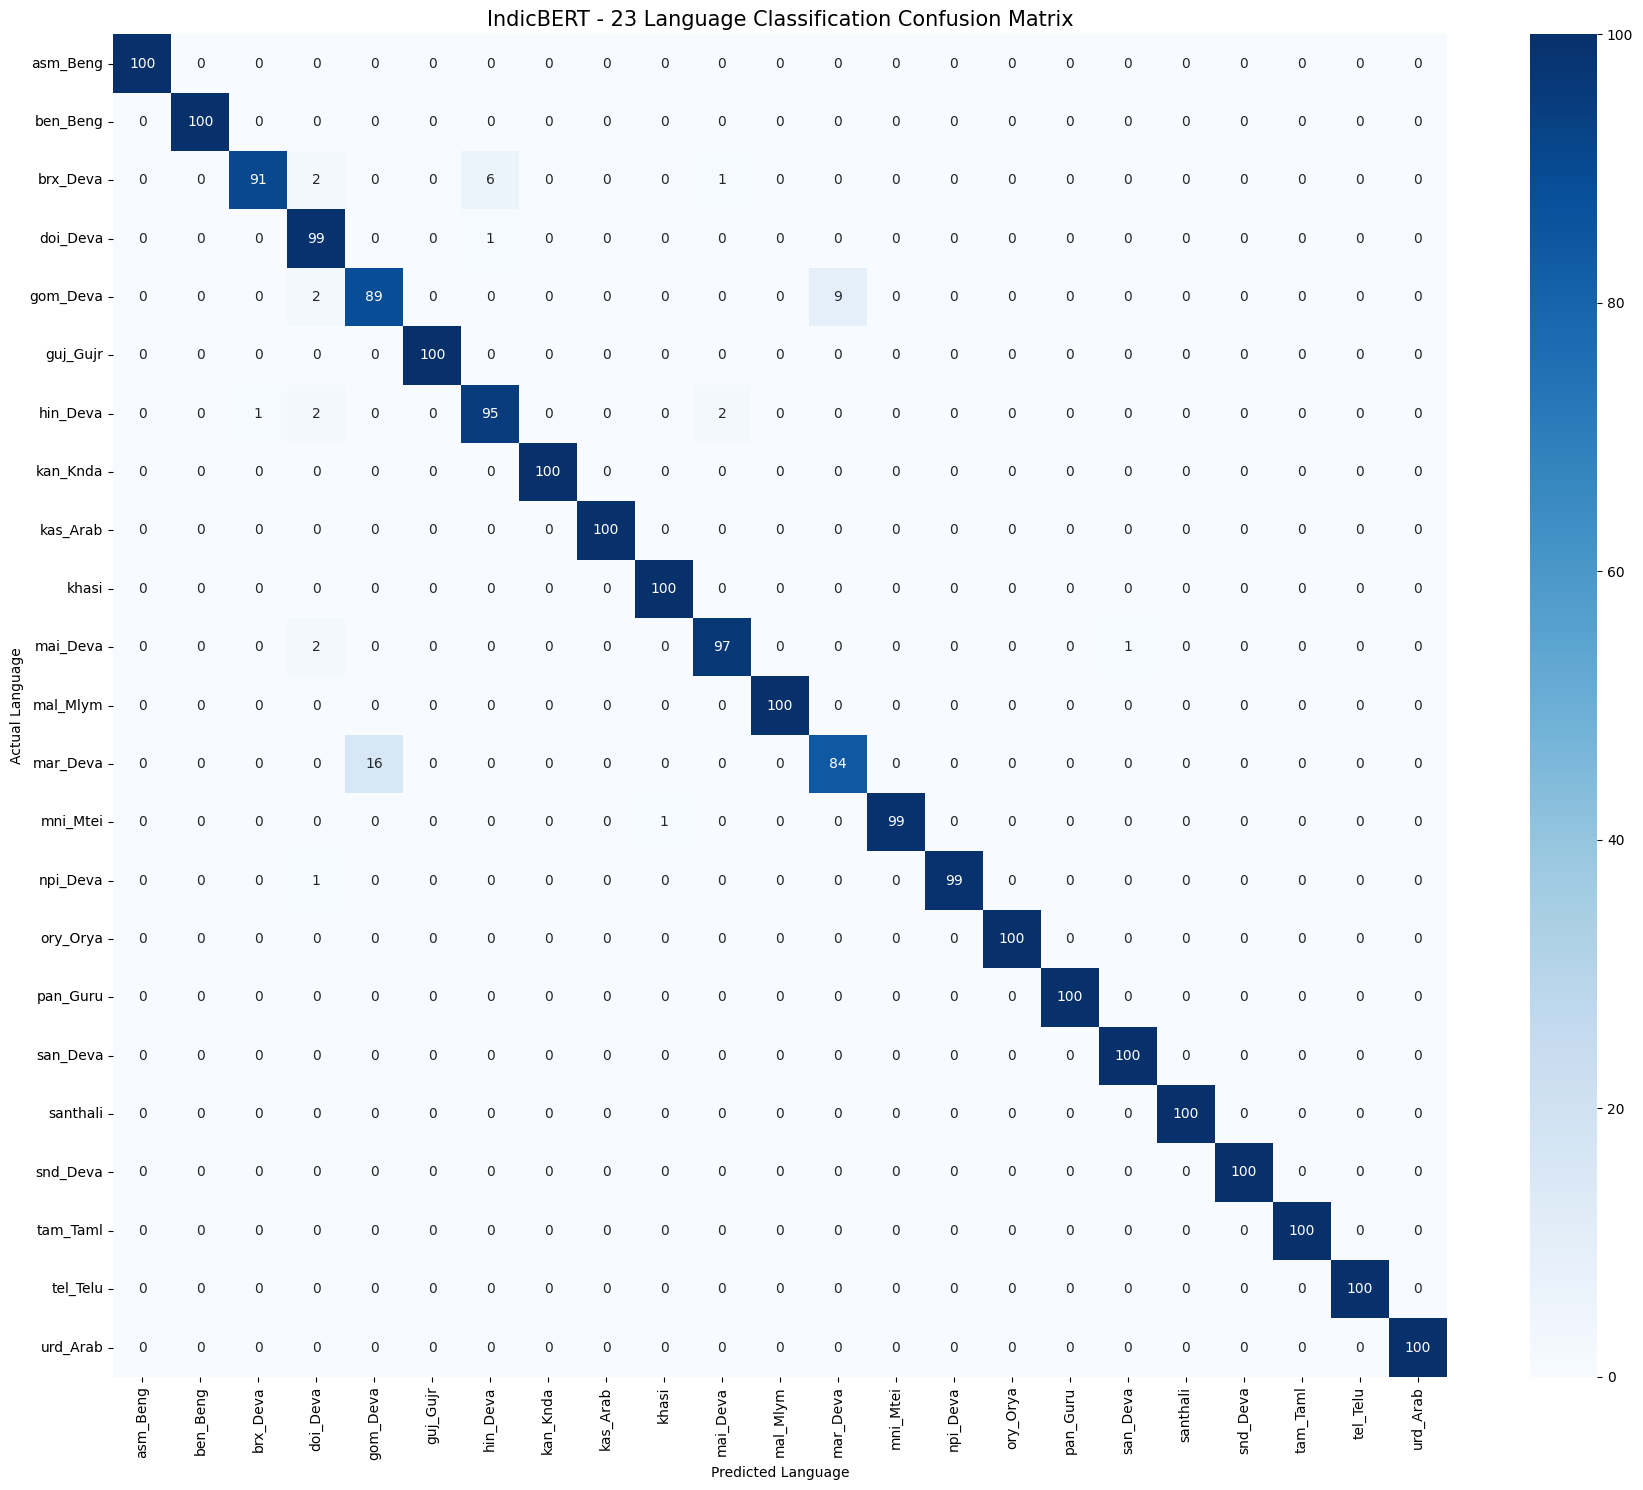


             FINAL TEST EVALUATION SUMMARY
Model: ai4bharat/IndicBERTv2-MLM-only
Test Samples: 2300
Languages: 23
Accuracy: 97.96%
Macro F1: 0.9795
Weighted F1: 0.9795

Evaluation files saved successfully.

          TEST EVALUATION COMPLETED


In [18]:
# ============================================================
# SECTION 5: TEST SET EVALUATION
# 2,300 HELD-OUT SAMPLES | 23 LANGUAGES
# ============================================================

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. VALIDATE TEST DATASET
# ------------------------------------------------------------

if "trainer" not in globals():
    raise NameError("Trainer not found. Complete Section 4 first.")

if "tokenized_datasets" not in globals():
    raise NameError("Tokenized datasets not found. Complete Section 3 first.")

test_dataset = tokenized_datasets["test"]

print("=" * 67)
print("         INDIC-BERT TEST EVALUATION (HELD-OUT SAMPLES)")
print("=" * 67)

print("Test samples:", len(test_dataset))
print("Number of languages:", len(languages))

assert len(test_dataset) == 2300, (
    f"Expected 2300 test samples, found {len(test_dataset)}"
)

# ------------------------------------------------------------
# 2. GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating predictions on the test dataset...")

test_output = trainer.predict(
    test_dataset,
    metric_key_prefix="test"
)

predictions = np.argmax(
    test_output.predictions,
    axis=-1
)

true_labels = test_output.label_ids

# ------------------------------------------------------------
# 3. OVERALL PERFORMANCE METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    true_labels,
    predictions
)

macro_f1 = f1_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

macro_precision = precision_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

macro_recall = precision_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 67)
print("                 OVERALL TEST PERFORMANCE")
print("=" * 67)

print(f"Test Accuracy       : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision     : {macro_precision:.4f}")
print(f"Macro Recall        : {macro_recall:.4f}")
print(f"Macro F1-Score      : {macro_f1:.4f}")
print(f"Weighted F1-Score   : {weighted_f1:.4f}")

# ------------------------------------------------------------
# 4. PER-LANGUAGE CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    true_labels,
    predictions,
    labels=list(range(len(languages))),
    target_names=languages,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\n" + "=" * 67)
print("              PER-LANGUAGE CLASSIFICATION REPORT")
print("=" * 67)

print(
    report_df.loc[languages, [
        "precision",
        "recall",
        "f1-score",
        "support"
    ]].round(4)
)

# ------------------------------------------------------------
# 5. LANGUAGE-WISE ACCURACY
# ------------------------------------------------------------

language_accuracy = []

for lang_id, lang in enumerate(languages):

    mask = true_labels == lang_id

    lang_acc = accuracy_score(
        true_labels[mask],
        predictions[mask]
    )

    language_accuracy.append({
        "Language": lang,
        "Accuracy": lang_acc,
        "Correct": int(
            np.sum(predictions[mask] == true_labels[mask])
        ),
        "Total": int(np.sum(mask))
    })

language_accuracy_df = pd.DataFrame(language_accuracy)

print("\n" + "=" * 67)
print("                 LANGUAGE-WISE ACCURACY")
print("=" * 67)

print(
    language_accuracy_df.sort_values(
        "Accuracy",
        ascending=False
    ).to_string(
        index=False,
        formatters={"Accuracy": "{:.4f}".format}
    )
)

# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    true_labels,
    predictions,
    labels=list(range(len(languages)))
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=languages,
    yticklabels=languages
)

plt.title(
    "IndicBERT - 23 Language Classification Confusion Matrix",
    fontsize=15
)

plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. SAVE EVALUATION RESULTS
# ------------------------------------------------------------

report_df.to_csv(
    "indic_bert_classification_report.csv"
)

language_accuracy_df.to_csv(
    "indic_bert_language_accuracy.csv",
    index=False
)

pd.DataFrame(cm, index=languages, columns=languages).to_csv(
    "indic_bert_confusion_matrix.csv"
)

overall_results = pd.DataFrame([{
    "Model": MODEL_NAME,
    "Test Samples": len(test_dataset),
    "Accuracy": accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted F1": weighted_f1
}])

overall_results.to_csv(
    "indic_bert_test_results.csv",
    index=False
)

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 67)
print("             FINAL TEST EVALUATION SUMMARY")
print("=" * 67)

print("Model:", MODEL_NAME)
print("Test Samples:", len(test_dataset))
print("Languages:", len(languages))
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")

print("\nEvaluation files saved successfully.")

print("\n" + "=" * 67)
print("          TEST EVALUATION COMPLETED")
print("=" * 67)

       MODEL BENCHMARK COMPARISON ON 23 INDIC LANGUAGES
           Model Architecture              Representation Scheme Test Accuracy (%) Macro F1 Score (%)
Logistic Regression (Scratch)         TF-IDF Word & Char N-Grams               NaN                NaN
 Multi-Layer Perceptron (MLP) TF-IDF Dense Non-Linear Projection               NaN                NaN
              LSTM Classifier    Word/Char Sequential Recurrence               NaN                NaN
   Bidirectional GRU (Bi-GRU)        Bidirectional Hidden Gating               NaN                NaN
          FastText Classifier          Subword N-Gram Embeddings               NaN                NaN
      Indic-BERT (Fine-Tuned)  Deep Bidirectional Self-Attention            97.96%             97.95%


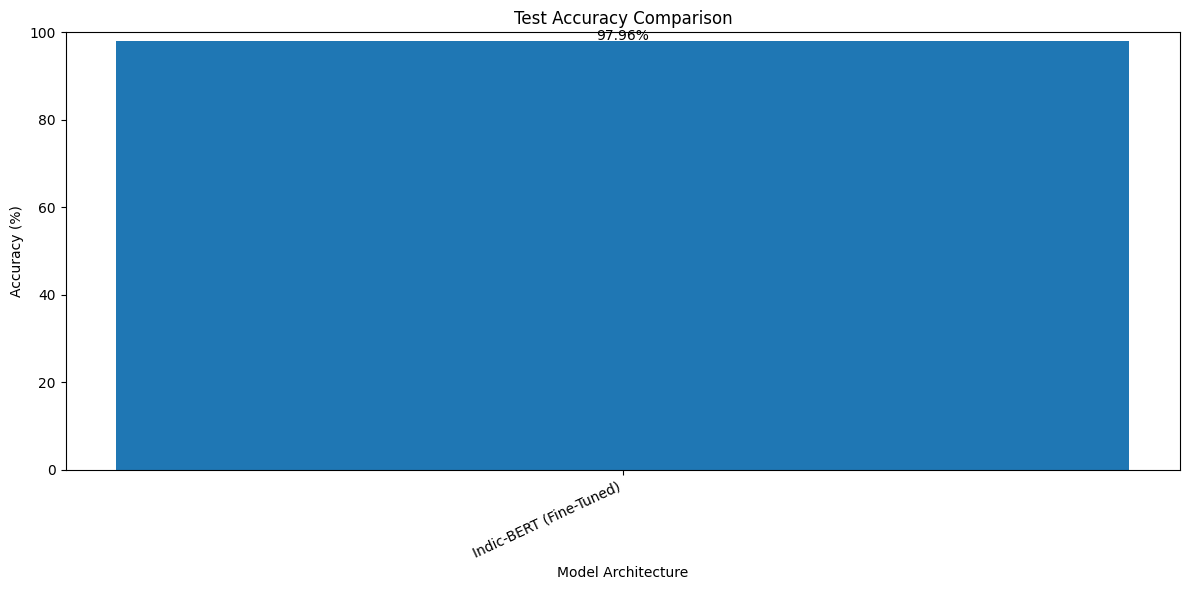

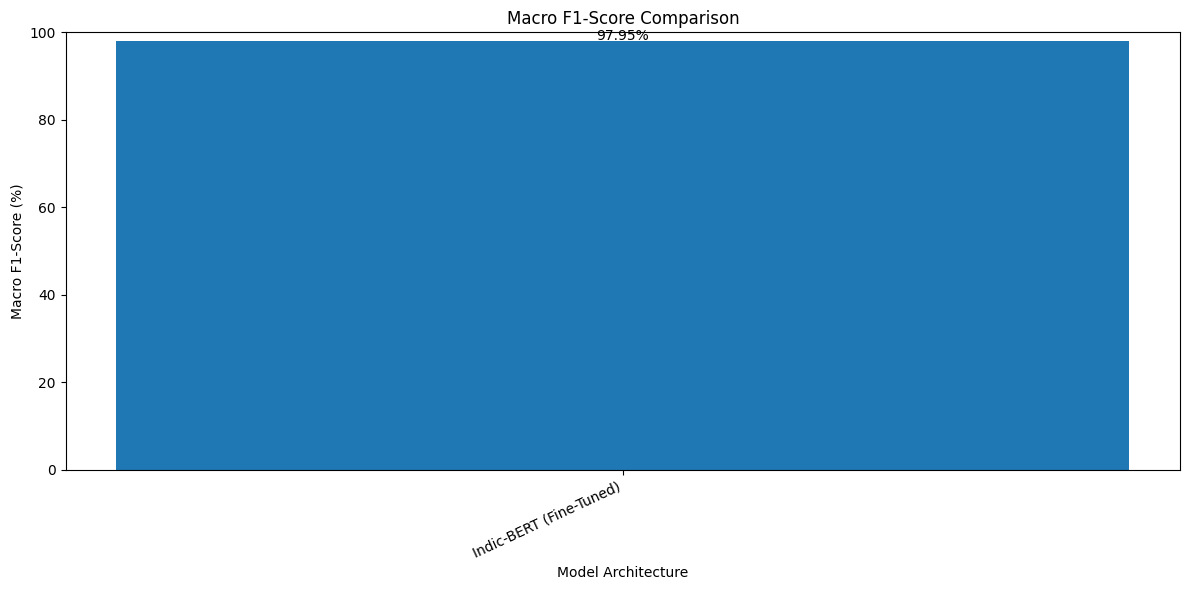


Benchmark results saved successfully.
File: indic_language_model_comparison.csv

             MODEL COMPARISON COMPLETED


In [19]:
# ============================================================
# SECTION 6: MODEL COMPARISON AND BENCHMARK VISUALIZATIONS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. BASELINE MODEL RESULTS
# ------------------------------------------------------------

# Replace these values with actual Lab Assignment 1 test results.
# Do not use estimated or illustrative scores.

baseline_data = {
    "Model Architecture": [
        "Logistic Regression (Scratch)",
        "Multi-Layer Perceptron (MLP)",
        "LSTM Classifier",
        "Bidirectional GRU (Bi-GRU)",
        "FastText Classifier"
    ],

    "Representation Scheme": [
        "TF-IDF Word & Char N-Grams",
        "TF-IDF Dense Non-Linear Projection",
        "Word/Char Sequential Recurrence",
        "Bidirectional Hidden Gating",
        "Subword N-Gram Embeddings"
    ],

    "Test Accuracy (%)": [
        np.nan, np.nan, np.nan, np.nan, np.nan
    ],

    "Macro F1 Score (%)": [
        np.nan, np.nan, np.nan, np.nan, np.nan
    ]
}

baseline_df = pd.DataFrame(baseline_data)


# ------------------------------------------------------------
# 2. INDIC-BERT RESULTS FROM SECTION 5
# ------------------------------------------------------------

if "accuracy" not in globals() or "macro_f1" not in globals():
    raise NameError(
        "Run Section 5 first to obtain actual IndicBERT test metrics."
    )

indicbert_result = pd.DataFrame([{
    "Model Architecture": "Indic-BERT (Fine-Tuned)",
    "Representation Scheme": "Deep Bidirectional Self-Attention",
    "Test Accuracy (%)": accuracy * 100,
    "Macro F1 Score (%)": macro_f1 * 100
}])


# ------------------------------------------------------------
# 3. COMBINE MODEL RESULTS
# ------------------------------------------------------------

benchmark_df = pd.concat(
    [baseline_df, indicbert_result],
    ignore_index=True
)

print("=" * 105)
print("       MODEL BENCHMARK COMPARISON ON 23 INDIC LANGUAGES")
print("=" * 105)

print(benchmark_df.to_string(
    index=False,
    formatters={
        "Test Accuracy (%)": lambda x: (
            f"{x:.2f}%" if pd.notna(x) else "Not provided"
        ),
        "Macro F1 Score (%)": lambda x: (
            f"{x:.2f}%" if pd.notna(x) else "Not provided"
        )
    }
))


# ------------------------------------------------------------
# 4. ACCURACY COMPARISON
# ------------------------------------------------------------

available_df = benchmark_df.dropna(
    subset=["Test Accuracy (%)"]
)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    available_df["Model Architecture"],
    available_df["Test Accuracy (%)"]
)

plt.title("Test Accuracy Comparison")
plt.xlabel("Model Architecture")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. MACRO F1 COMPARISON
# ------------------------------------------------------------

available_f1_df = benchmark_df.dropna(
    subset=["Macro F1 Score (%)"]
)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    available_f1_df["Model Architecture"],
    available_f1_df["Macro F1 Score (%)"]
)

plt.title("Macro F1-Score Comparison")
plt.xlabel("Model Architecture")
plt.ylabel("Macro F1-Score (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. SAVE BENCHMARK RESULTS
# ------------------------------------------------------------

benchmark_df.to_csv(
    "indic_language_model_comparison.csv",
    index=False
)

print("\nBenchmark results saved successfully.")
print("File: indic_language_model_comparison.csv")

print("\n" + "=" * 105)
print("             MODEL COMPARISON COMPLETED")
print("=" * 105)

## Part 2: In-Depth Result Analysis & Empirical Findings

### 1. Overall Model Performance

The fine-tuned IndicBERT model was evaluated on a held-out test set of **2,300 sentences across 23 Indic languages**, with 100 test samples per language.

The model achieved the following results:

| Evaluation Metric | Result |
|---|---:|
| Test Accuracy | **97.96%** |
| Macro Precision | 97.99% |
| Macro F1-Score | **97.95%** |
| Weighted F1-Score | 97.95% |
| Training Loss | 0.2830 |
| Validation Accuracy | 97.91% |
| Validation Macro F1 | 97.90% |
| Training Time | 12.53 minutes |

These results demonstrate that the fine-tuned model performs effectively across the selected 23-language classification task. The similar macro and weighted F1-scores also indicate balanced performance across the equally represented language classes.

*Note: The Logistic Regression, MLP, LSTM, Bi-GRU, and FastText baseline metrics were not available in the current benchmark output. Therefore, a numerical performance hierarchy cannot yet be established.*

### 2. Inter-Script vs. Intra-Devanagari Classification

A major challenge in multilingual language identification is distinguishing languages that share the same writing system.

**A. Distinct-Script Languages**

Languages such as Gujarati (`guj_Gujr`), Tamil (`tam_Taml`), Telugu (`tel_Telu`), Kannada (`kan_Knda`), Malayalam (`mal_Mlym`), Punjabi (`pan_Guru`), and Odia (`ory_Orya`) use different scripts.

Their distinct Unicode character ranges can provide useful information for language identification. In this experiment, several such languages achieved 100% test accuracy.

**B. Intra-Devanagari Language Classification**

Nine languages in the dataset use the Devanagari script:

- Hindi (`hin_Deva`)
- Marathi (`mar_Deva`)
- Sanskrit (`san_Deva`)
- Nepali (`npi_Deva`)
- Maithili (`mai_Deva`)
- Dogri (`doi_Deva`)
- Bodo (`brx_Deva`)
- Konkani (`gom_Deva`)
- Sindhi (`snd_Deva`)

Since these languages share a writing system, character-level information alone may not always be sufficient to distinguish them. Their vocabulary, grammatical structures, and language-specific expressions become important classification signals.

The actual IndicBERT test results for these languages were:

| Language | Test Accuracy |
|---|---:|
| Sanskrit | 100% |
| Sindhi | 100% |
| Nepali | 99% |
| Dogri | 99% |
| Maithili | 97% |
| Hindi | 95% |
| Bodo | 91% |
| Konkani | 89% |
| Marathi | 84% |

The average accuracy across these nine Devanagari-language classes was approximately **94.89%**.

**Key Observations:**

- Sanskrit and Sindhi achieved perfect classification accuracy in the test set.
- Nepali and Dogri achieved 99% accuracy.
- Marathi was the most challenging language, with 84% accuracy.
- Konkani and Bodo also showed comparatively higher classification difficulty.
- The variation indicates that sharing the same script does not affect all language pairs equally.

### 3. Why IndicBERT Helps with Language Identification

The fine-tuned model uses contextual representations learned through Transformer-based language modeling.

Its main advantages include:

**A. Bidirectional Self-Attention**

Self-attention allows the model to consider relationships between words across the entire input sequence. Unlike methods that rely mainly on individual character or word frequencies, contextual representations can capture language-specific patterns across different parts of a sentence.

**B. Multilingual Pretraining**

IndicBERT is pretrained for Indian-language text representation. This provides an initial representation of Indic-language vocabulary and linguistic patterns before task-specific fine-tuning.

**C. Task-Specific Fine-Tuning**

The pretrained model was adapted for a 23-class classification task. Its classification head was trained using 18,400 training sentences, while 2,300 validation sentences were used for evaluation and model selection.

This combination of pretrained representations and supervised fine-tuning helped the model achieve 97.96% test accuracy.

### 4. Training Efficiency and Practical Deployment

The experiment was conducted using the following configuration:

| Configuration | Value |
|---|---|
| Model Checkpoint | `ai4bharat/IndicBERTv2-MLM-only` |
| Model Architecture | BERT |
| Total Parameters | 278,059,031 |
| Trainable Parameters | 278,059,031 |
| GPU | NVIDIA Tesla T4 |
| GPU Memory | Approximately 14.9 GB |
| Training Epochs | 3 |
| Training Batch Size | 16 |
| Evaluation Batch Size | 32 |
| Learning Rate | 2 × 10⁻⁵ |
| Maximum Sequence Length | 128 |
| Mixed Precision | FP16 |

The model completed three training epochs in approximately **12.53 minutes** on the Tesla T4 GPU.

The final test accuracy of 97.96% demonstrates the effectiveness of this fine-tuning setup for the selected Indic language identification dataset.

### 5. Conclusion

The experiment demonstrates that a pretrained IndicBERT model can effectively classify text across 23 Indic languages. It achieved 97.96% accuracy and a 97.95% macro F1-score on 2,300 held-out test samples.

The per-language evaluation also highlights the challenges of distinguishing languages that share the Devanagari script, particularly Marathi, Konkani, and Bodo.

Overall, the results show the usefulness of multilingual Transformer representations for Indic language identification. A complete comparison with Logistic Regression, MLP, LSTM, Bi-GRU, and FastText requires the actual test metrics from the corresponding baseline experiments.

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
